Boundary Value Problems for ODEs, Additional Exercises

By Pablo Angulo, Fabricio Macià and Daniel Sánchez-Mendoza for ETSIN@UPM

# Boundary value problems for ordinary differential equations

In [44]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as integ
from scipy.special import airy

## Exercise 1:

The simply supported beam carries a uniform load of intensity $w_0$ and the tensile force $N$. The vertical displacement $v$ can be computed as follows.

![](Beam.png)

First solve the following boundary-value problem:
$$ y^{(iv)} - \gamma y'' = 1,\qquad y(0)=y''(0)=0,\quad y(1)=y''(1)=0, $$
where  
$$ \gamma = \frac{NL^2}{EI}, $$
and $EI$ is the bending rigidity. The vertical displacement at a point $0\leq x \leq L$ is then given by:
$$ v(x) =  \frac{w_0 L^4}{EI} y \left(\frac{x}{L}\right).$$

- Compute the solution $y$ of the boundary value problem for $\gamma =  1.65929$ and $\gamma = -1.65929$. Plot the resulting functions $y(t)$.

- Suppose  $w_0L^2/N= 1.5$. Compute the maximum displacement $\max_{0\leq x\leq L}|v(x)|$ for the two cases studied above.

## Exercise 2:

We want to solve the following boundary value problem:

$$y'''=−\frac{1}{x}y''+\frac{1}{x^2}y'+0.1(y')^3,$$

with $1\leq x\leq 2$ and

$$y(1) = 0,\quad  y''(1) = 0, \quad y(2) = 1.$$

- Compute the solution using `solve_bvp`; plot the result thus obtained.

In [45]:
def fun(x, yt):
    "Defines the ODE"
    y, yp, ys = yt
    return [yp,ys, -(ys/x)+(yp/(x**2))+(0.1*(yp**3))] #aqui ponemos yp e ys porque asi la hacenos de primer grado


# Boundary conditions
a, b = 1, 2
alpha, beta = 0, 1


def bc(vals_a, vals_b):
    # vals_a contains the values y(a) and y'(a)
    ya, ypa, ysa = vals_a
    # vals_b contains the values y(b) and y'(b)
    yb, ypb, ysb = vals_b
    return np.array([ya - alpha, ysa - alpha, yb - beta]) #porque la funcion en a (1) vale alpha (0) y asi las demás

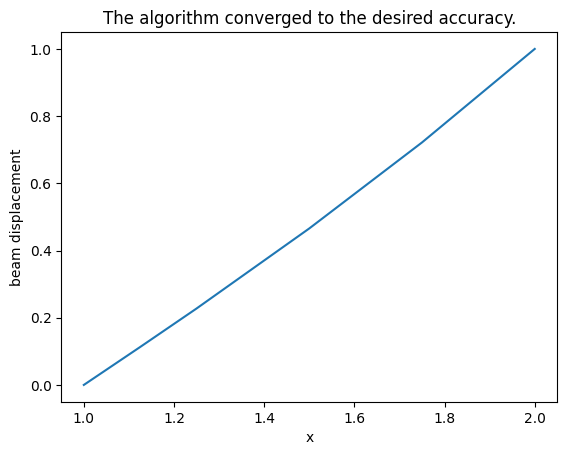

In [46]:
N = 5
xs = np.linspace(a, b, N)
yt = np.zeros((3, N))
sol = integ.solve_bvp(fun, bc, xs, yt)
plt.title(sol["message"])
plt.xlabel("x")
plt.ylabel("beam displacement")
plt.plot(sol["x"], sol["y"][0, :])
plt.show()

- Is it possible to use the finite element code seen in class to solve this problem? If yes, compute the solution with this method. Otherwise, explain why it is not possible.

## Exercise 3:

We are going to study a steady, incompressible, laminar flow along a pipe with an annular section, axis $Ox$ and radius
$$
0<R_1<R_2.
$$
The flow is laminar if the velocity field is parallel to the axis of the pipe and is only a function of the distance $r$ from the axis of the pipe. Together with the incompressibility condition, this results in a velocity field of the form:
$$
(u(r),0,0).
$$
In the presence of a constant pressure gradient
$$
-\frac{d P}{d x} = G
$$
the velocity field satisfies the Navier-Stokes equations:
$$
\mu \left({\frac {d ^{2}u}{d r^{2}}}+{\frac {1}{r}}{\frac {d u}{d r}}\right)=-G,\quad R_1\leq r \leq R_2,
$$
where $\mu$ is the dynamic viscosity coefficient, together with the no-splip conditions at the pipe walls:
$$
u(R_1)=u(R_2)=0.
$$

- Suppose the pipe radii are $R_1=1\,\mathrm{cm}$ and $R_2=5\,\mathrm{cm}$, that mercury ($\mu = 1.53\times 10^{-3}\,\mathrm{Pa\,s}$) flows through it, and that the pressure gradient between the two ends of the pipe is $G=20\,\mathrm{Pa}$. Solve the resulting boundary problem and represent the solution graphically.

In [47]:
G=20
mu=1.53e-3

def fun(r, ys):
    "Defines the ODE"
    y, yp = ys
    return [yp, (-G/mu)-(yp/r)]


# Boundary conditions
a, b = 1, 5
alpha, beta = 0, 0


def bc(vals_a, vals_b):
    # vals_a contains the values y(a) and y'(a)
    ya, ypa = vals_a
    # vals_b contains the values y(b) and y'(b)
    yb, ypb,= vals_b
    return np.array([ya - alpha, yb - beta]) #porque la funcion en a (1) vale alpha (0) y asi las demás

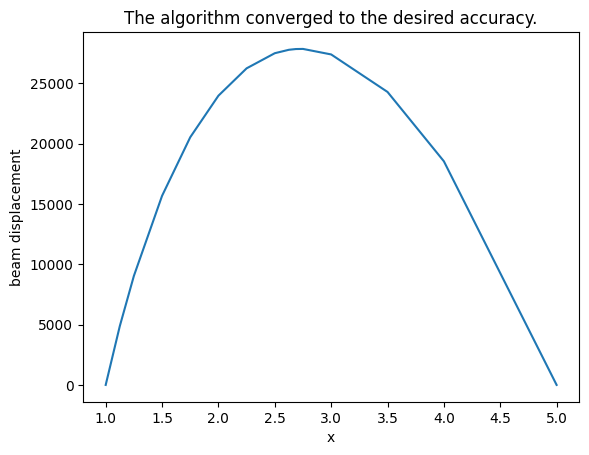

In [48]:
N = 5
xs = np.linspace(a, b, N)
ys = np.zeros((2, N))
sol = integ.solve_bvp(fun, bc, xs, ys)
plt.title(sol["message"])
plt.xlabel("x")
plt.ylabel("beam displacement")
plt.plot(sol["x"], sol["y"][0, :])
plt.show()

- Construct a function that assigns the maximum fluid velocity to a value of the largest pipe radius $R_2$. Represent it graphically for values ​​$2\,\mathrm{cm}\leq R_2 \leq 10\,\mathrm{cm}$.

## Exercise 4:

The Blasius boundary layer is the boundary layer that forms around a semi-infinite plate placed parallel to a steady unidirectional flow. The component of the fluid velocity parallel to the plate is described, in a suitable coordinate system, by:
$$
u(x) = U f'(x), \quad u(0)=0,\quad u(R)= U,
$$
where the constant $U$ is a reference velocity, $R>0$ is large compared to $U$, and the profile $f$ satisfies the differential equation
$$
f'''(x)=-f''(x)f(x)
$$
together with the boundary conditions:
$$
f(0)=f'(0)=0,\quad f'(R)=1.
$$
- Solve the boundary problem for $f$ with $U=2$ and $R=6$. Graphically represent the velocity parallel to the plate $u(x)$.

In [49]:
U=2

def fun(x, ys):
    "Defines the ODE"
    y, yp, ypp = ys
    return [yp,ypp, -ypp*y] 


# Boundary conditions
a, b = 0, R
alpha, beta = 0, 1


def bc(vals_a, vals_b):
    # vals_a contains the values y(a) and y'(a)
    ya, ypa, yppa = vals_a
    # vals_b contains the values y(b) and y'(b)
    yb, ypb, yppb = vals_b
    return np.array([ya - alpha, ypa - alpha, ypb - beta]) 

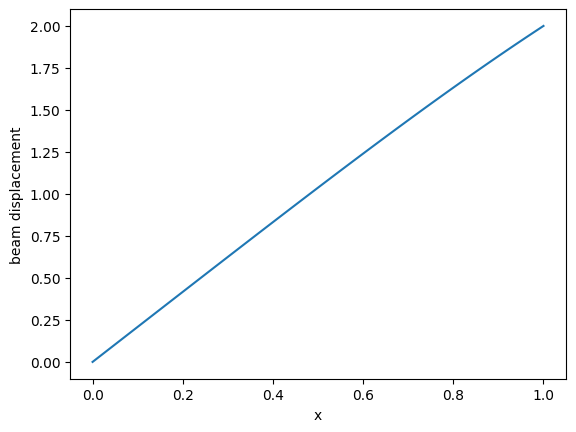

In [50]:
N = 50
xs = np.linspace(a, b, N)
ys = np.zeros((3, N))
sol = integ.solve_bvp(fun, bc, xs, ys)

plt.xlabel("x")
plt.ylabel("beam displacement")
plt.plot(sol["x"], U*sol["y"][1, :]) #Pq en el enunciado te dan Fprima(x)*u
plt.show()

## Exercise 5:
We consider the following (academic) variant of the **Orr–Sommerfeld** equation that models the small perturbation behavior of a laminar flow in a channel of height $R$. The stream function $f$ satisfies:
$$
-\frac{1}{\mathrm{Re}}(f^{(iv)}(x) + 2f''(x) - f(x))=(Ux-c)(f''(x)-f(x))+F(x)
$$
together with the boundary conditions:
$$
f(0)=f'(0)=0,\quad f(R)=f'(R)=0.
$$
- Solve the boundary problem for $f$ with $U=10$, $\mathrm{Re} = 3$, $c=1$ and $R=1$, taking $F(x)=\mathrm{Ai}(x)$. Graphically represent the solution.

In [57]:
from scipy.special import airy
U=10
Re=3
c=1

def fun(x, ys):
    "Defines the ODE"
    y, yp, ypp, yppp = ys
    return [yp,ypp,yppp, ((U*x-c)*(ypp-y)+airy(x)[0])*(-Re)-2*ypp+y] 

R=1
# Boundary conditions
a, b = 0, R
alpha, beta = 0, 0


def bc(vals_a, vals_b):
    # vals_a contains the values y(a) and y'(a)
    ya, ypa, yppa, ypppa = vals_a
    # vals_b contains the values y(b) and y'(b)
    yb, ypb, yppb, ypppb = vals_b
    return np.array([ya - alpha, ypa - alpha, yb - beta, ypb - beta]) 

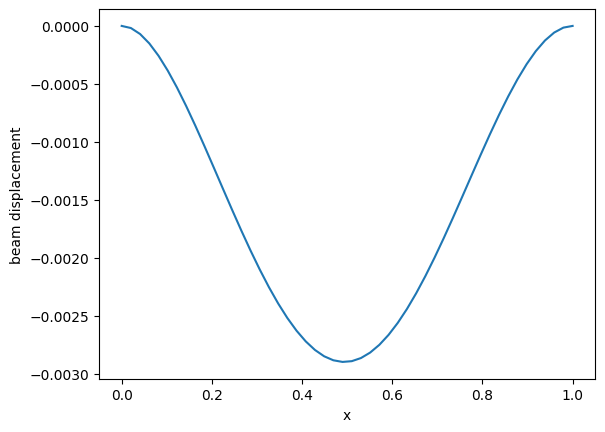

In [58]:
N = 50
xs = np.linspace(a, b, N)
ys = np.zeros((4, N))
sol = integ.solve_bvp(fun, bc, xs, ys)

plt.xlabel("x")
plt.ylabel("beam displacement")
plt.plot(sol["x"],sol["y"][0, :])
plt.show()